In [2]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [3]:
#Direccion de la pagina web
url= "https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population"
#Identificamos solicitud
headers = {
    "User-Agent": "PracticaEducativaPython/1.0 (aprendizaje personal)"
}

#Solicita la pagina
response = requests.get(url, headers=headers, timeout=20)

#Comprueba la respuesta
print("Código de respuesta:", response.status_code)

#Muestra una pequena parte del contenido
print(response.text[:500])

Código de respuesta: 200
<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientp


In [4]:
#Convierte HTML en un objeto BeautifulSoup
soup = BeautifulSoup(response.text, "html.parser")

#Busca todas las tablas de la pagina
tablas = soup.find_all("table")

#Cuenta cuantas tablas encontramos
print("Cantidad de tablas encontradas:", len(tablas))


Cantidad de tablas encontradas: 3


In [5]:
#recorre las tablas encontramos 
for i, tabla in enumerate(tablas):

    #Busca los encabezados de cada tabla
    encabezados = tabla.find_all("th")

    #Extrae su texto
    nombres = [th.get_text(" ", strip=True) for th in encabezados]
                               
    print(f"Tabla {i}:")
    print(nombres[:10])
    print("-------------")                       
                               
                               
    

Tabla 0:
['Location', 'Population', '% of world', 'Date', 'Source (official or from the United Nations )', 'Notes']
-------------
Tabla 1:
['v t e Lists of countries by population statistics', 'Global', 'Continents/subregions', 'Intercontinental', 'Cities/urban areas', 'Past and future', 'Population density', 'Growth indicators', 'Life expectancy', 'Other demographics']
-------------
Tabla 2:
['v t e World']
-------------


In [6]:
%pip install lxml html5lib beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


In [7]:
from io import StringIO

#Selecciona la primera tabla
tabla_poblacion = tablas[0]

#Convierte la tabla del HTML  un DataFrame
df = pd.read_html(StringIO(str(tabla_poblacion)))[0]

#Mostramos las priemras 5 filas
display(df.head())

,Location,Population,% of world,Date,Source (official or from the United Nations),Notes
0,World,8.232000e+09,100%,13 Jun 2025,UN projection[1][3],NaN
1,India,1.429404e+09,17.3%,1 Jul 2026,Official projection[4],[b]
2,China,1.404890e+09,17.0%,31 Dec 2025,Official estimate[5],[c]
3,United States,3.417849e+08,4.1%,1 Jul 2025,Official estimate[6],[d]
4,Indonesia,2.901251e+08,3.5%,30 Jun 2026,National annual projection[7],NaN


In [8]:
#Conocer la dimension de la tabla
print("Dimensiones:", df.shape)

#Conocer nombres columnas
print("\nColumnas:")
print(df.columns.tolist())

#Conocer tipos de datos
print("\nInformacion general:")
df.info()

#Contar los valores nulos
print("\nValores nulos:")
print(df.isnull().sum())


Dimensiones: (241, 6)

Columnas:
['Location', 'Population', '% of world', 'Date', 'Source (official or from the United Nations)', 'Notes']

Informacion general:
<class 'pandas.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 6 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Location                                      240 non-null    str    
 1   Population                                    240 non-null    float64
 2   % of world                                    240 non-null    str    
 3   Date                                          240 non-null    str    
 4   Source (official or from the United Nations)  240 non-null    str    
 5   Notes                                         33 non-null     str    
dtypes: float64(1), str(5)
memory usage: 23.5 KB

Valores nulos:
Location                                          1
Population                   

In [9]:
#copia de datos originales
df_limpio = df.copy()

#Seleccionar columnas necesarias
df_limpio = df_limpio[
    ["Location", "Population", "% of world", "Date"]
]
#Eliminar  filas sin pais o poblacion
df_limpio = df_limpio.dropna(
    subset=["Location", "Population"]
)
#Exluir el total mundial
df_limpio = df_limpio[df_limpio["Location"] != "World"].copy()
#Renombrar columnas
df_limpio = df_limpio.rename(columns={
    "Location": "Pais",
    "Population": "Poblacion",
    "% of world": "Porcentaje_Mundial",
    "Date": "Fecha"
})
#Mostrar los primeros registros
display(df_limpio.head())
#Mostrar dimensiones
print("Dimensiones:", df_limpio.shape)

,Pais,Poblacion,Porcentaje_Mundial,Fecha
1,India,1.429404e+09,17.3%,1 Jul 2026
2,China,1.404890e+09,17.0%,31 Dec 2025
3,United States,3.417849e+08,4.1%,1 Jul 2025
4,Indonesia,2.901251e+08,3.5%,30 Jun 2026
5,Pakistan,2.414994e+08,2.9%,1 Mar 2023


Dimensiones: (239, 4)


In [11]:
#Seleccionar los 10 paises con mayor poblacion
top_10 = df_limpio.sort_values(
    by= "Poblacion",
    ascending=False
).head(10)
#Mostrar resultados
display(top_10)

,Pais,Poblacion,Porcentaje_Mundial,Fecha
1,India,1.429404e+09,17.3%,1 Jul 2026
2,China,1.404890e+09,17.0%,31 Dec 2025
3,United States,3.417849e+08,4.1%,1 Jul 2025
4,Indonesia,2.901251e+08,3.5%,30 Jun 2026
5,Pakistan,2.414994e+08,2.9%,1 Mar 2023
6,Nigeria,2.238000e+08,2.7%,1 Jul 2023
7,Brazil,2.142120e+08,2.6%,1 Jul 2026
8,Bangladesh,1.698289e+08,2.1%,14 Jun 2022
9,Russia,1.460283e+08,1.8%,1 Jan 2025
10,Mexico,1.312319e+08,1.6%,30 Jun 2026


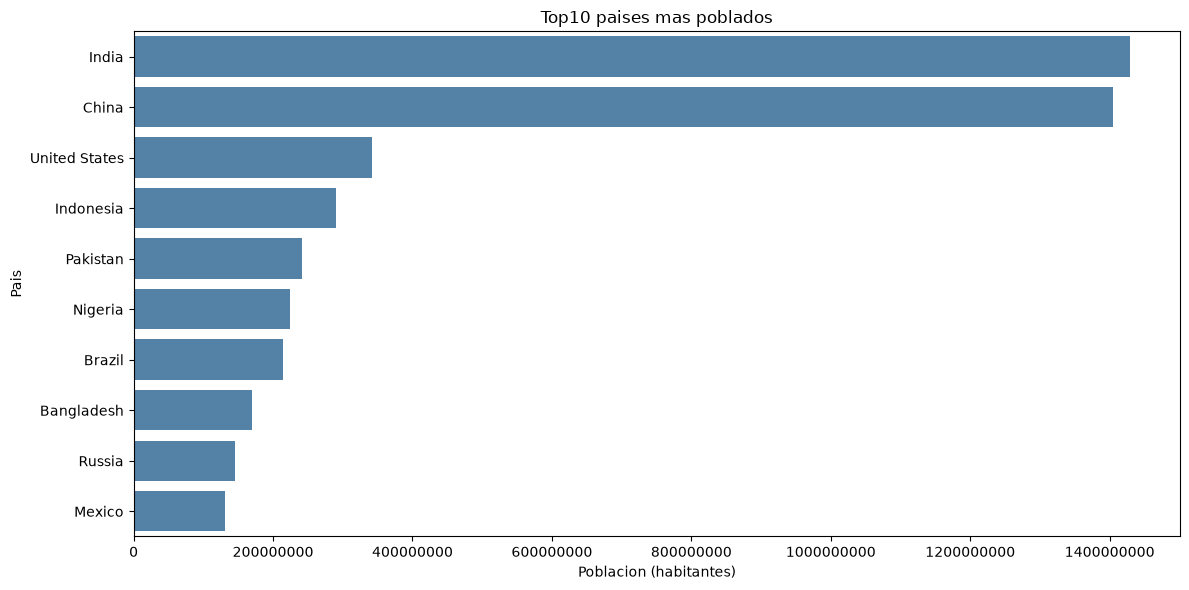

In [12]:
#Crear el espacio para la grafica
plt.figure(figsize=(12, 6))
#Construir la grafica de barras
sns.barplot(
    data=top_10,
    x="Poblacion",
    y="Pais",
    color="steelblue"
)
#Agregar titulos y etiquetas
plt.title("Top10 paises mas poblados")
plt.xlabel("Poblacion (habitantes)")
plt.ylabel("Pais")
#Mejorar el formato de los numeros
plt.ticklabel_format(
    style="plain",
    axis="x"
)
#Ajustar elementos
plt.tight_layout()
#Mostrar grafica
plt.show()

In [16]:
#crear conexion SQLite
conn = sqlite3.connect(":memory:")
#Guardar Dataframe en tabla SQL
df_limpio.to_sql(
    "paises",
    conn, 
    if_exists="replace",
    index=False
)

print("Base de datos creada correctamente")

Base de datos creada correctamente


In [17]:
query = """
SELECT
    Pais,
    Poblacion
FROM paises
ORDER BY Poblacion DESC
LIMIT 5;
"""
resultado = pd.read_sql_query(query, conn)
display(resultado)

,Pais,Poblacion
0,India,1.429404e+09
1,China,1.404890e+09
2,United States,3.417849e+08
3,Indonesia,2.901251e+08
4,Pakistan,2.414994e+08


In [18]:
query = """
SELECT 
    Pais,
    Poblacion
FROM paises
WHERE Poblacion > 100000000
ORDER BY Poblacion DESC;
"""
resultado_100m = pd.read_sql_query(query, conn)
display(resultado_100m)
print("Cantidad de registros:", len(resultado_100m))

,Pais,Poblacion
0,India,1.429404e+09
1,China,1.404890e+09
2,United States,3.417849e+08
3,Indonesia,2.901251e+08
4,Pakistan,2.414994e+08
5,Nigeria,2.238000e+08
6,Brazil,2.142120e+08
7,Bangladesh,1.698289e+08
8,Russia,1.460283e+08
9,Mexico,1.312319e+08


Cantidad de registros: 16


In [20]:
#exportar datos limpios
df_limpio.to_csv(
    "poblacion_paises.csv",
    index=False,
    encoding="utf-8-sig"
)

#Exportar resultado consulta SQL
resultado_100m.to_csv(
    "paises_mas_100_millones.csv",
    index=False,
    encoding="utf-8-sig"
)
    
print("Archivos CSV generados")
    

Archivos CSV generados
